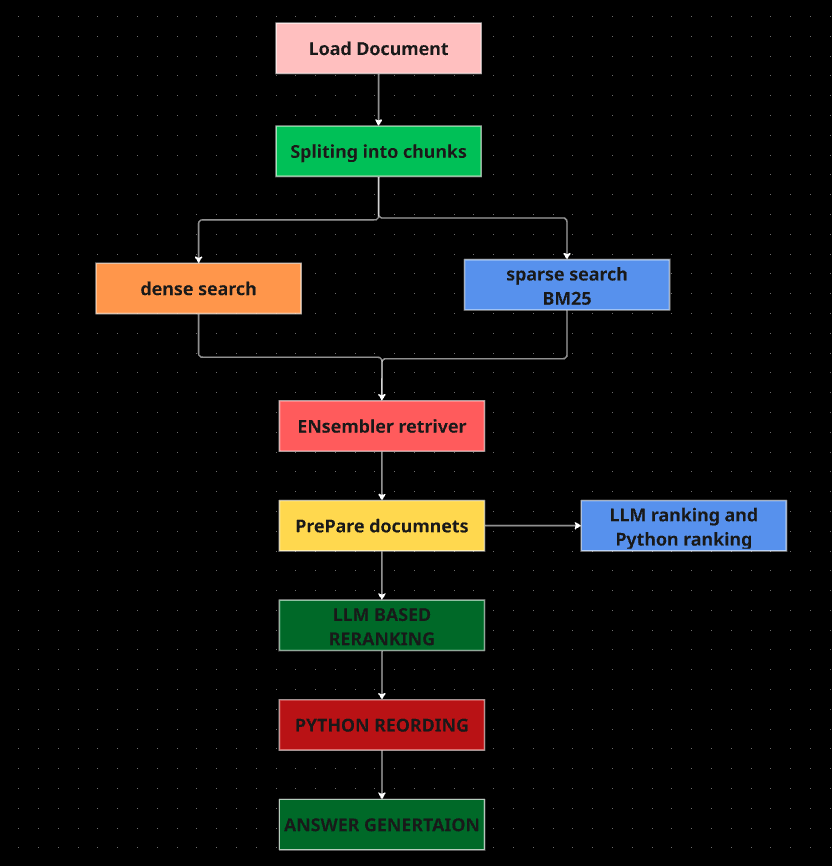
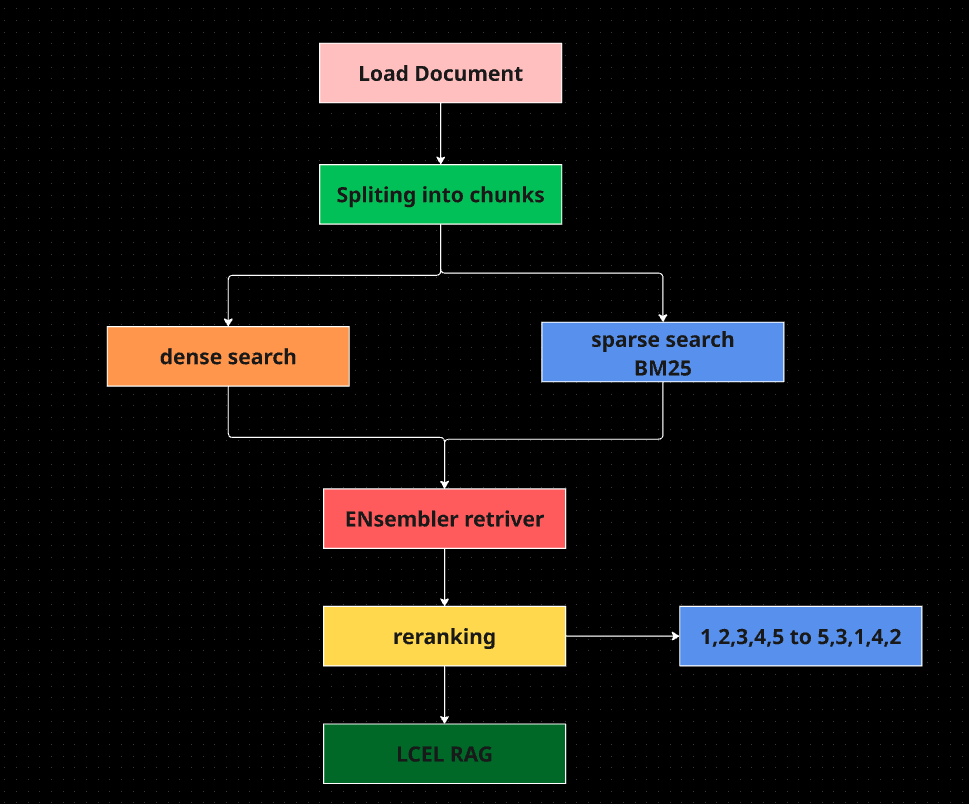

In [ ]:
from pathlib import Path

from langchain_community.document_loaders import (
    DirectoryLoader,
    TextLoader
)

from langchain_text_splitters import RecursiveCharacterTextSplitter

from langchain_huggingface import HuggingFaceEmbeddings

from langchain_community.vectorstores import FAISS
from langchain_community.retrievers import BM25Retriever

from langchain_classic.retrievers import EnsembleRetriever


from langchain_core.prompts import ChatPromptTemplate
from langchain_core.output_parsers import StrOutputParser
from langchain_core.runnables import RunnablePassthrough,RunnableLambda

from langchain_groq import ChatGroq

/var/folders/m8/jv_qd8md6_n84v8zcshwvjm40000gn/T/ipykernel_30307/1694730157.py:3: DeprecationWarning: `langchain-community` is being sunset and is no longer actively maintained. See https://github.com/langchain-ai/langchain-community/issues/674 for details and migration guidance toward standalone integration packages.
  from langchain_community.document_loaders import (
/Volumes/ManojData/github/ITK-FREE-GENAI-SERIES-NOTES/.ITK-FREE-GENAI-SERIES-NOTES/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
dir_loader = DirectoryLoader(
    "data",
    glob="*.txt",
    loader_cls=TextLoader,
)

documents = dir_loader.load()
print(f"total documents loaded: {len(documents)}")

total documents loaded: 5


In [3]:
for i,doc in enumerate(documents):
    print(f"Documents {i+1}")
    print(f"source: {doc.metadata.get('source')}")
    print(doc.page_content[:30])

Documents 1
source: data/python.txt
Python is a high-level, interp
Documents 2
source: data/docker.txt
Docker is a platform used to b
Documents 3
source: data/kubernetes.txt
# KUBERNETES QUESTIONS AND ANS
Documents 4
source: data/langchain_intro.txt
LangChain is a flexible framew
Documents 5
source: data/award.txt
 
# Anant Nag and the Dadasahe


In [4]:
# Chunking

text_splitter = RecursiveCharacterTextSplitter(
    chunk_size = 500,
    chunk_overlap = 50,
    separators=["\n\n", "\n", " ", ""]
)

chunks = text_splitter.split_documents(documents)

print(f"Total Documents : {len(documents)}")
print(f"Total Chunks created: {len(chunks)}")

Total Documents : 5
Total Chunks created: 127


In [5]:
# create embedings
embeding_model = HuggingFaceEmbeddings(
    model_name="sentence-transformers/all-MiniLM-L6-v2"
)

Loading weights: 100%|██████████| 103/103 [00:00<00:00, 5960.28it/s]


In [6]:
dense_vectorstore = FAISS.from_documents(
    chunks,
    embeding_model
)

In [7]:
dense_retriver = dense_vectorstore.as_retriever(
    search_kwargs={"k": 3} # k=3 requests the three most relevant chunks from the vector store.
)

In [8]:
query = "who created python"

dense_result = dense_retriver.invoke(query)

for i, doc in enumerate(dense_result, start=1):
    print(f"\nDense Result {i}")
    print(doc.page_content)


Dense Result 1
Python is a high-level, interpreted, general-purpose programming language
known for its simple syntax and readability.

Python was created by Guido van Rossum. Development began in the late
1980s, and Python was first released in 1991.

Python is widely used in software development, automation, data science,
artificial intelligence, machine learning, web development, and DevOps.
Python provides many built-in libraries and has a large ecosystem of
third-party packages.

Dense Result 2
Frameworks such as FastAPI, Flask, and Django help developers build web
applications and APIs. Python is also popular in automation because
developers can easily write scripts for managing infrastructure,
processing files, interacting with APIs, and performing repetitive tasks.

Its simplicity and versatility make Python one of the most widely used
programming languages in modern technology.

Dense Result 3
He made his Kannada film debut with Sankalp and later entered Hindi cinema with Shya

# BM25 / SPARSE retriver

In [9]:
sparse_retriver = BM25Retriever.from_documents (chunks)
sparse_retriver.k=5

In [16]:
query = "who created Python"
sparse_result = sparse_retriver.invoke(query)

for i, doc in enumerate(sparse_result, start=1):
    print(f"\n saprse result {i}")
    print(doc.page_content)


 saprse result 1
Python is a high-level, interpreted, general-purpose programming language
known for its simple syntax and readability.

Python was created by Guido van Rossum. Development began in the late
1980s, and Python was first released in 1991.

Python is widely used in software development, automation, data science,
artificial intelligence, machine learning, web development, and DevOps.
Python provides many built-in libraries and has a large ecosystem of
third-party packages.

 saprse result 2
Frameworks such as FastAPI, Flask, and Django help developers build web
applications and APIs. Python is also popular in automation because
developers can easily write scripts for managing infrastructure,
processing files, interacting with APIs, and performing repetitive tasks.

Its simplicity and versatility make Python one of the most widely used
programming languages in modern technology.

 saprse result 3
He also spoke about his connection with Karnataka and India, describing Karnat

In [17]:
hybrid_retriver = EnsembleRetriever(
    retrievers=[
        dense_retriver,
        sparse_retriver
    ],
    weights=[0.7,0.3]
)

In [42]:
query = "What is LangChain"

hybrid_results = hybrid_retriver.invoke(query)

for i, doc in enumerate(hybrid_results, start=1):
    print(f"\nHybrid Result {i}")
    print(f"Source: {doc.metadata.get('source')}")
    print(doc.page_content)


Hybrid Result 1
Source: data/langchain_intro.txt
LangChain is a flexible framework designed for developing applications powered by large language models (LLMs). It provides tools and abstractions to work with LLMs more effectively and includes components for prompt management, chains, memory, and agents.

Hybrid Result 2
Source: data/langchain_intro.txt
LangChain supports tool integration including web search, calculators, and APIs, allowing LLMs to interact with external systems and respond more accurately to dynamic queries.
Memory in LangChain enables context retention across multiple steps in a conversation or task, making the application more coherent and stateful.

Hybrid Result 3
Source: data/langchain_intro.txt
LangChain integrates with many third-party services such as OpenAI, Hugging Face, and Cohere. This enables developers to experiment with different models and optimize performance for specific use cases like summarization, question answering, or translation.

Hybrid Resu

In [ ]:
query = "who created Langchain"

retrieved_docs = hybrid_retriver.invoke(query)

print("STEP 1: Hybrid Retrieval Results")
print("=" * 50)

for i, doc in enumerate(retrieved_docs, start=1):
    print(f"\nDocument {i}")
    print(f"Source: {doc.metadata.get('source')}")
    print(doc.page_content)

STEP 1: Hybrid Retrieval Results

Document 1
Source: data/langchain_intro.txt
LangChain is a flexible framework designed for developing applications powered by large language models (LLMs). It provides tools and abstractions to work with LLMs more effectively and includes components for prompt management, chains, memory, and agents.

Document 2
Source: data/langchain_intro.txt
LangChain integrates with many third-party services such as OpenAI, Hugging Face, and Cohere. This enables developers to experiment with different models and optimize performance for specific use cases like summarization, question answering, or translation.

Document 3
Source: data/langchain_intro.txt
LangChain supports tool integration including web search, calculators, and APIs, allowing LLMs to interact with external systems and respond more accurately to dynamic queries.
Memory in LangChain enables context retention across multiple steps in a conversation or task, making the application more coherent and stat

In [43]:
def format_docs(docs):
    formatted_docs = ""

    for i, doc in enumerate(docs, start=1):
        formatted_docs += f"""
Document {i}
Source: {doc.metadata.get('source')}

Content:
{doc.page_content}

-------------------------
"""

    return formatted_docs


formatted_docs = format_docs(retrieved_docs)

print("STEP 2: Formatted Documents")
print(formatted_docs)

STEP 2: Formatted Documents

Document 1
Source: data/langchain_intro.txt

Content:
LangChain is a flexible framework designed for developing applications powered by large language models (LLMs). It provides tools and abstractions to work with LLMs more effectively and includes components for prompt management, chains, memory, and agents.

-------------------------

Document 2
Source: data/langchain_intro.txt

Content:
LangChain integrates with many third-party services such as OpenAI, Hugging Face, and Cohere. This enables developers to experiment with different models and optimize performance for specific use cases like summarization, question answering, or translation.

-------------------------

Document 3
Source: data/langchain_intro.txt

Content:
LangChain supports tool integration including web search, calculators, and APIs, allowing LLMs to interact with external systems and respond more accurately to dynamic queries.
Memory in LangChain enables context retention across multiple

In [ ]:
import os
from dotenv import load_dotenv
load_dotenv(override=True)


True

In [44]:
from langchain_groq import ChatGroq
llm = ChatGroq(
    model = "openai/gpt-oss-120b"
)


In [45]:
prompt = ChatPromptTemplate.from_template("""
You are a document reranking assistant.

User Question:
{question}

Documents:
{documents}

Task:
Rank all documents from most relevant to least relevant
to the user's question.

Rules:
- Use only the document numbers provided.
- Return each document number once.
- Use 1-based numbering: Document 1, Document 2, etc.
- Return only comma-separated numbers.
- Do not provide explanations.

Example output:
3,1,2,4
""")




In [46]:
reranking_chain = prompt | llm | StrOutputParser()

In [47]:
response = reranking_chain.invoke({
    "question": query,
    "documents":formatted_docs
})

print("Step:3 LLM ReRanking")

print(response)

Step:3 LLM ReRanking
1,2,3,4,5,6,7,8


In [48]:
indices = []

for x in response.split(","):
    x.strip()

    if x.isdigit():
        index = int(x) - 1
        indices.append(index)

print("step4: python indecies")
print(indices)

step4: python indecies
[0, 1, 2, 3, 4, 5, 6, 7]


In [49]:
reranked_docs = []

for i in indices:
    if 0 <= i < len(retrieved_docs):
        doc = retrieved_docs[i]
        reranked_docs.append(doc)

print("STEP 5: Reranked Documents")
print("=" * 50)

for i, doc in enumerate(reranked_docs, start=1):
    print(f"\nReranked Position: {i}")
    print(f"Source: {doc.metadata.get('source')}")
    print(doc.page_content)

STEP 5: Reranked Documents

Reranked Position: 1
Source: data/langchain_intro.txt
LangChain is a flexible framework designed for developing applications powered by large language models (LLMs). It provides tools and abstractions to work with LLMs more effectively and includes components for prompt management, chains, memory, and agents.

Reranked Position: 2
Source: data/langchain_intro.txt
LangChain integrates with many third-party services such as OpenAI, Hugging Face, and Cohere. This enables developers to experiment with different models and optimize performance for specific use cases like summarization, question answering, or translation.

Reranked Position: 3
Source: data/langchain_intro.txt
LangChain supports tool integration including web search, calculators, and APIs, allowing LLMs to interact with external systems and respond more accurately to dynamic queries.
Memory in LangChain enables context retention across multiple steps in a conversation or task, making the applicatio

In [50]:
query = "What is Langchain"
reranked_context = format_docs(reranked_docs)

answer_prompt = ChatPromptTemplate.from_template("""
Answer the question using the context below.

Question:
{question}

Context:
{context}

If the answer is not present in the context, say you don't know.
""")

answer_chain = answer_prompt | llm | StrOutputParser()

answer = answer_chain.invoke({
    "question": query,
    "context": reranked_context
})

print("FINAL ANSWER")
print(answer)

FINAL ANSWER
LangChain is a flexible framework for building applications that use large language models (LLMs). It offers tools and abstractions such as prompt management, chains, memory, and agents, and can integrate with third‑party services (e.g., OpenAI, Hugging Face, Cohere) and external tools like web search, calculators, and APIs to enable more powerful and stateful LLM‑driven applications.
